# 01 — Data Collection

This notebook builds the multi-modal Alaska wildfire dataset (optical + SAR + thermal + weather).

By default it uses the **synthetic data generator** (`src/data/synthetic_data.py`) so it runs
immediately with no credentials. Section 3 shows how to switch to real Google Earth Engine data.


In [1]:
import sys, os
sys.path.append(os.path.abspath('..'))

import yaml
import numpy as np
import matplotlib.pyplot as plt

from src.data.synthetic_data import AlaskaWildfireSyntheticDataset, spatial_block_split

with open('../config/config.yaml') as f:
    cfg = yaml.safe_load(f)

cfg['data']

{'use_synthetic': True,
 'n_samples': 1200,
 'patch_size': 32,
 'n_optical_bands': 4,
 'n_sar_bands': 2,
 'n_thermal_bands': 1,
 'weather_seq_len': 30,
 'n_weather_features': 5,
 'horizons': [1, 3, 6],
 'classes': ['NO_RISK', 'MODERATE', 'HIGH'],
 'raw_dir': 'data/raw',
 'processed_dir': 'data/processed'}

## real satellite data (Google Earth Engine)

run the cell below:
1. A GEE account + `earthengine authenticate` run once from your terminal
2. `config/config.yaml` -> `data.use_synthetic: false`
3. Your Alaska AOI filled in `src/data/gee_pipeline.py::get_default_aoi()`

This will pull real Sentinel-1/2, MODIS/VIIRS, and ERA5 composites instead of synthetic tensors.

In [5]:
from src.data.gee_pipeline import init_earth_engine, get_default_aoi, build_feature_stack

ee = init_earth_engine()
aoi = get_default_aoi()
feature_stack = build_feature_stack(aoi, start_date='2024-05-01', end_date='2024-05-31')
print(feature_stack.bandNames().getInfo())

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


['B4', 'B3', 'B8', 'B11', 'VV', 'VH', 'MaxFRP']


In [6]:
import folium
m = folium.Map(location=[64.5, -147.1], zoom_start=7)
folium.Rectangle(bounds=[[63.5, -148.9], [65.5, -145.3]], color='red').add_to(m)
m


5943 fire perimeters loaded


<Axes: >

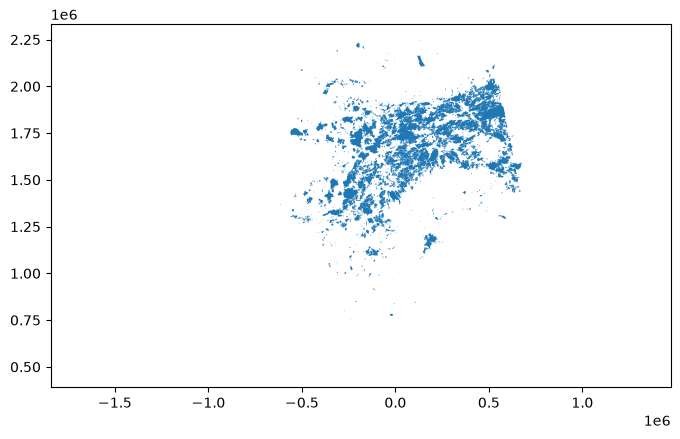

In [7]:
from src.data.gee_pipeline import load_afs_fire_perimeters 

perimeters = load_afs_fire_perimeters('../data/raw/AlaskaFireHistory_PerimeterPolygons_AKAlbersNAD83_geojson/AlaskaFireHistory_Polygons_AKAlbersNAD83_geojson.geojson') 
print(len(perimeters), 'fire perimeters loaded') 
perimeters.head() 
perimeters.plot(figsize=(8,8))

In [8]:
# print(perimeters.crs)
""""
Check the file's actual coordinate system
 It should print something like 
 PROJCS["NAD83 / Alaska Albers"]... or an EPSG code like 3338. This confirms the mismatch.
"""

'"\nCheck the file\'s actual coordinate system\n It should print something like \n PROJCS["NAD83 / Alaska Albers"]... or an EPSG code like 3338. This confirms the mismatch.\n'

608 fires within the Fairbanks AOI


<Axes: >

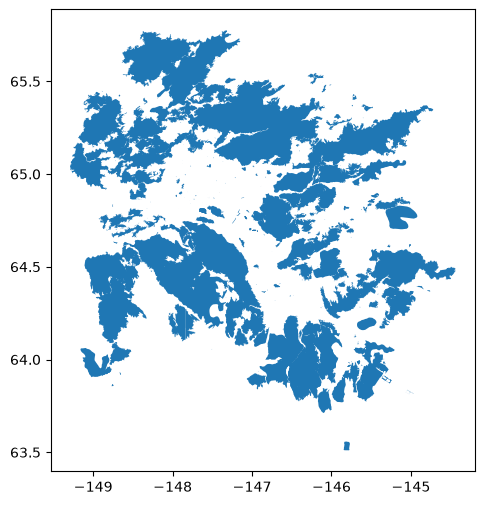

In [9]:
perimeters = perimeters.to_crs(epsg=4326) 
fairbanks_fires = perimeters.cx[-148.9:-145.3, 63.5:65.5] 
print(len(fairbanks_fires), 'fires within the Fairbanks AOI') 
fairbanks_fires.plot(figsize=(6,6))

Text(49.13686240158394, 0.5, 'Latitude')

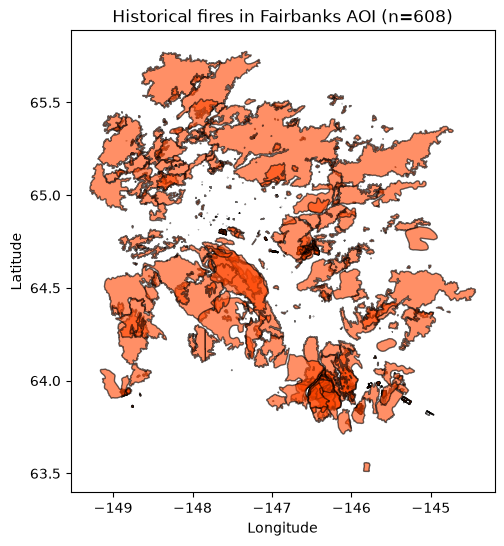

In [10]:
ax = fairbanks_fires.plot(figsize=(6,6), edgecolor='black', facecolor='orangered', alpha=0.6) 
ax.set_title(f'Historical fires in Fairbanks AOI (n={len(fairbanks_fires)})') 
ax.set_xlabel('Longitude'); 
ax.set_ylabel('Latitude')

In [11]:
fairbanks_fires.columns

Index(['OBJECTID', 'NAME', 'RECORDNUMBER', 'ACRES', 'AFSNUMBER', 'DOFNUMBER',
       'USFSNUMBER', 'ADDNUMBER', 'PERIMETERDATE', 'LATESTPERIMETER', 'SOURCE',
       'SOURCEMETHOD', 'SOURCECLASS', 'AGENCYACRES', 'ACREAGEMETHOD',
       'COMMENTS', 'FIREID', 'FIREYEAR', 'UPDATETIME', 'USEDONFINALREPORT',
       'FPOUTDATE', 'FPMERGEDDATE', 'IRWINID', 'PRESCRIBED', 'FIRESEASONS',
       'Shape_Length', 'Shape_Area', 'geometry'],
      dtype='str')

In [12]:
fairbanks_fires[['NAME', 'FIREYEAR', 'geometry' ]].head()

,NAME,FIREYEAR,geometry
3,Washington Creek,2025,"POLYGON ((-147.86292 65.15701, -147.86245 65.1..."
4,Camp,2025,"POLYGON ((-145.49612 64.47597, -145.4965 64.47..."
23,Hunts,2025,"POLYGON ((-146.65154 64.73159, -146.65154 64.7..."
27,Obrien,2025,"MULTIPOLYGON (((-147.96121 65.27836, -147.9607..."
47,Ninetyeight,2025,"MULTIPOLYGON (((-146.18199 64.57827, -146.1817..."


In [13]:
from src.data.labeling import generate_sample_grid, assign_risk_labels
sample_dates = ['2018-06-01', '2019-06-01', '2020-06-01', '2021-06-01', '2022-06-01', '2023-06-01'] 
points = generate_sample_grid(bounds=(-148.9, 63.5, -145.3, 65.5), sample_dates=sample_dates, spacing_deg=0.1) 
print(len(points), 'sample points generated')

4320 sample points generated


In [18]:
labeled_points = assign_risk_labels(perimeters, points, horizon_months=1, buffer_km=30) 
labeled_points['risk_label'].value_counts() #This is the real, historically-grounded label for every (location, date)

risk_label
NO_RISK     3108
MODERATE    1209
HIGH           3
Name: count, dtype: int64

In [15]:
import os, time 
from src.data.gee_pipeline import get_feature_patch, get_weather_series
import numpy as np 
os.makedirs('../data/processed', exist_ok=True) 
label_map = {'NO_RISK': 0, 'MODERATE': 1, 'HIGH': 2}

In [17]:
import ee

for i, row in labeled_points.iterrows():
    out_path = f'../data/processed/patch_{i}.npz'
    if os.path.exists(out_path):
        continue  # resumable: skips work already done

    pt = ee.Geometry.Point([row.geometry.x, row.geometry.y])
    date_str = row['sample_date'].strftime('%Y-%m-%d')

    try:
        spatial = get_feature_patch(pt, date_str, patch_size_px=32)
        weather = get_weather_series(pt, date_str, seq_len=30)
        label = label_map[row['risk_label']]
        np.savez(out_path, spatial=spatial, weather=weather, label=label)
    except Exception as e:
        print(f'Skipped point {i} ({date_str}): {e}')

    time.sleep(0.3)  # stay under GEE's rate limit

Skipped point 0 (2018-06-01): Image.select: Band pattern 'B4' was applied to an Image with no bands. See https://developers.google.com/earth-engine/guides/debugging#no-bands
Skipped point 1 (2018-06-01): Image.select: Band pattern 'B4' was applied to an Image with no bands. See https://developers.google.com/earth-engine/guides/debugging#no-bands
Skipped point 2 (2018-06-01): Image.select: Band pattern 'B4' was applied to an Image with no bands. See https://developers.google.com/earth-engine/guides/debugging#no-bands
Skipped point 3 (2018-06-01): Image.select: Band pattern 'B4' was applied to an Image with no bands. See https://developers.google.com/earth-engine/guides/debugging#no-bands
Skipped point 4 (2018-06-01): Image.select: Band pattern 'B4' was applied to an Image with no bands. See https://developers.google.com/earth-engine/guides/debugging#no-bands
Skipped point 5 (2018-06-01): Image.select: Band pattern 'B4' was applied to an Image with no bands. See https://developers.google

KeyboardInterrupt: 

In [19]:
from tqdm import tqdm
for i, row in tqdm(labeled_points.iterrows(), total=len(labeled_points)):
    ...

100%|██████████| 4320/4320 [00:00<00:00, 5893.35it/s]
